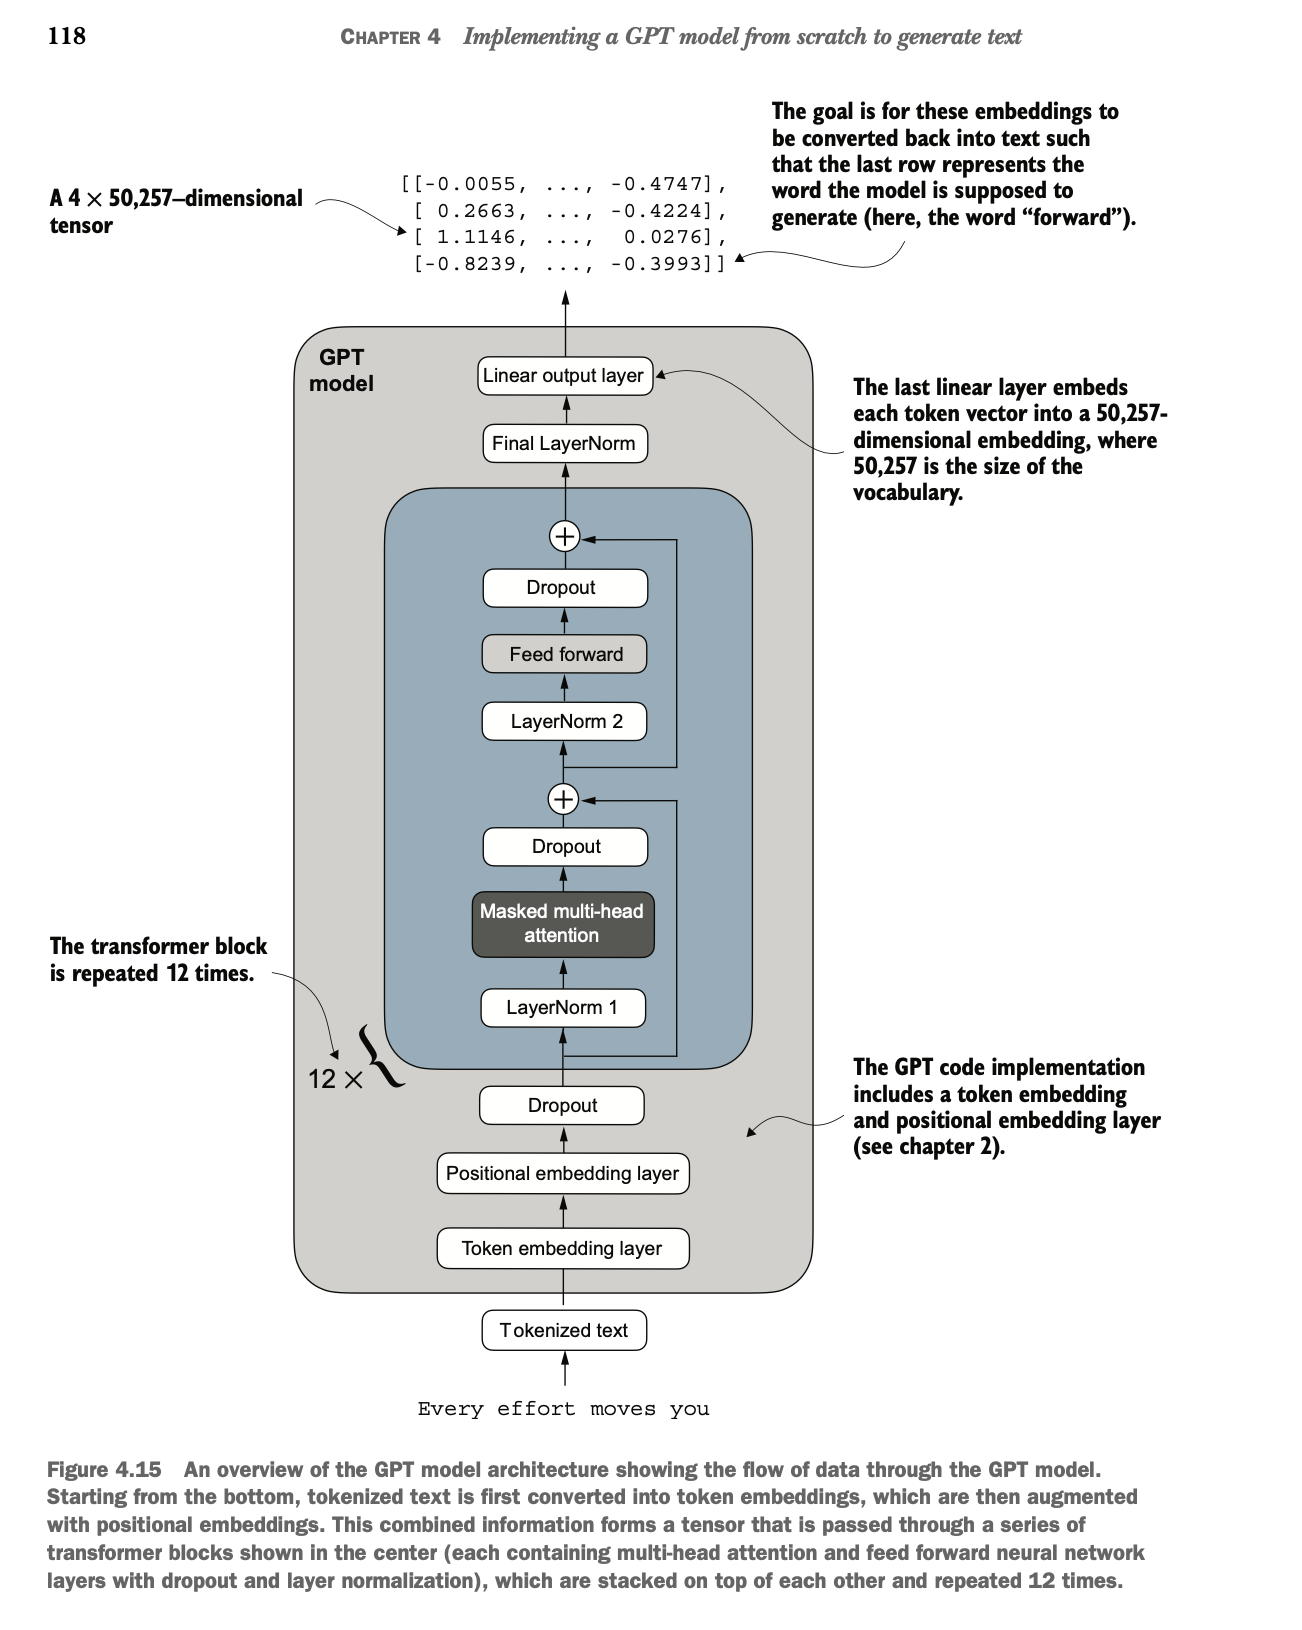


In [ ]:
import torch
import torch.nn as nn

try:
    from notebook_setup import (
        FeedForward,
        GPT_CONFIG_124M,
        LayerNorm,
        MultiHeadAttention,
        TransformerBlock,
        batch,
        generate_text_simple,
        tokenizer,
    )
except ModuleNotFoundError:
    from CH04_Implementing_a_GPT_model_from_scratch_to_generate_text.notebook_setup import (
        FeedForward,
        GPT_CONFIG_124M,
        LayerNorm,
        MultiHeadAttention,
        TransformerBlock,
        batch,
        generate_text_simple,
        tokenizer,
    )


class GPTModel(nn.Module):

    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))

        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)

        return logits


# Using the configuration of the 124M parameter model,
# we can now instantiate this GPT model with random initial weights as follows:

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

total_params = sum(p.numel() for p in model.parameters())
print(
    f"\nTotal number of parameters: {total_params:,}"
)  # shows 163 mil params due to GPT 2's weight typing

# To understand better, let’s take a look at
# the shapes of the token embedding layer and
# linear output layer that we initialized on
# the model via the GPTModel earlier:
print("\nToken embedding layer shape:", model.tok_emb.weight.shape)
print("\nOutput layer shape:", model.out_head.weight.shape)

In [ ]:
# Let’s remove the output layer parameter
# count from the total GPT-2 model count according to the weight tying:

total_params_gpt2 = total_params - sum(p.numel() for p in model.out_head.parameters())
print(
    f"Number of trainable parameters "
    f"considering weight tying: {total_params_gpt2:,}"
)

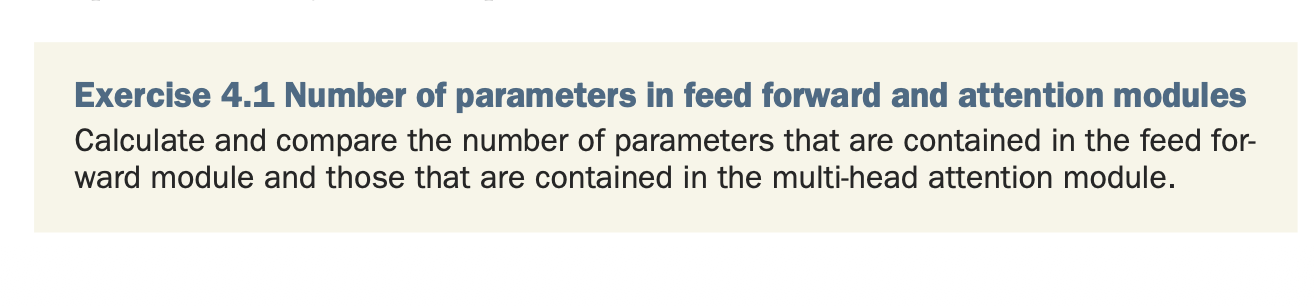


In [ ]:
torch.manual_seed(123)
model_feed_forward = FeedForward(GPT_CONFIG_124M)

total_params_feed_forward = sum(p.numel() for p in model_feed_forward.parameters())

print(
    f"Total number of parameters in feed forward module: {total_params_feed_forward:,}"
)
# model_multi_head_attention = MultiHeadAttention(
#     GPT_CONFIG_124M
# )
# total_params_mhd = sum(p.numel() for p in model_multi_head_attention.parameters())
# print(f"Total number of parameters in attention module: {total_params:,}")

In [ ]:
# Calculate the total size in bytes (assuming float32, 4 bytes per parameter)
total_size_bytes = total_params * 4

# Convert to megabytes
total_size_mb = total_size_bytes / (1024 * 1024)

print(f"Total size of the model: {total_size_mb:.2f} MB")

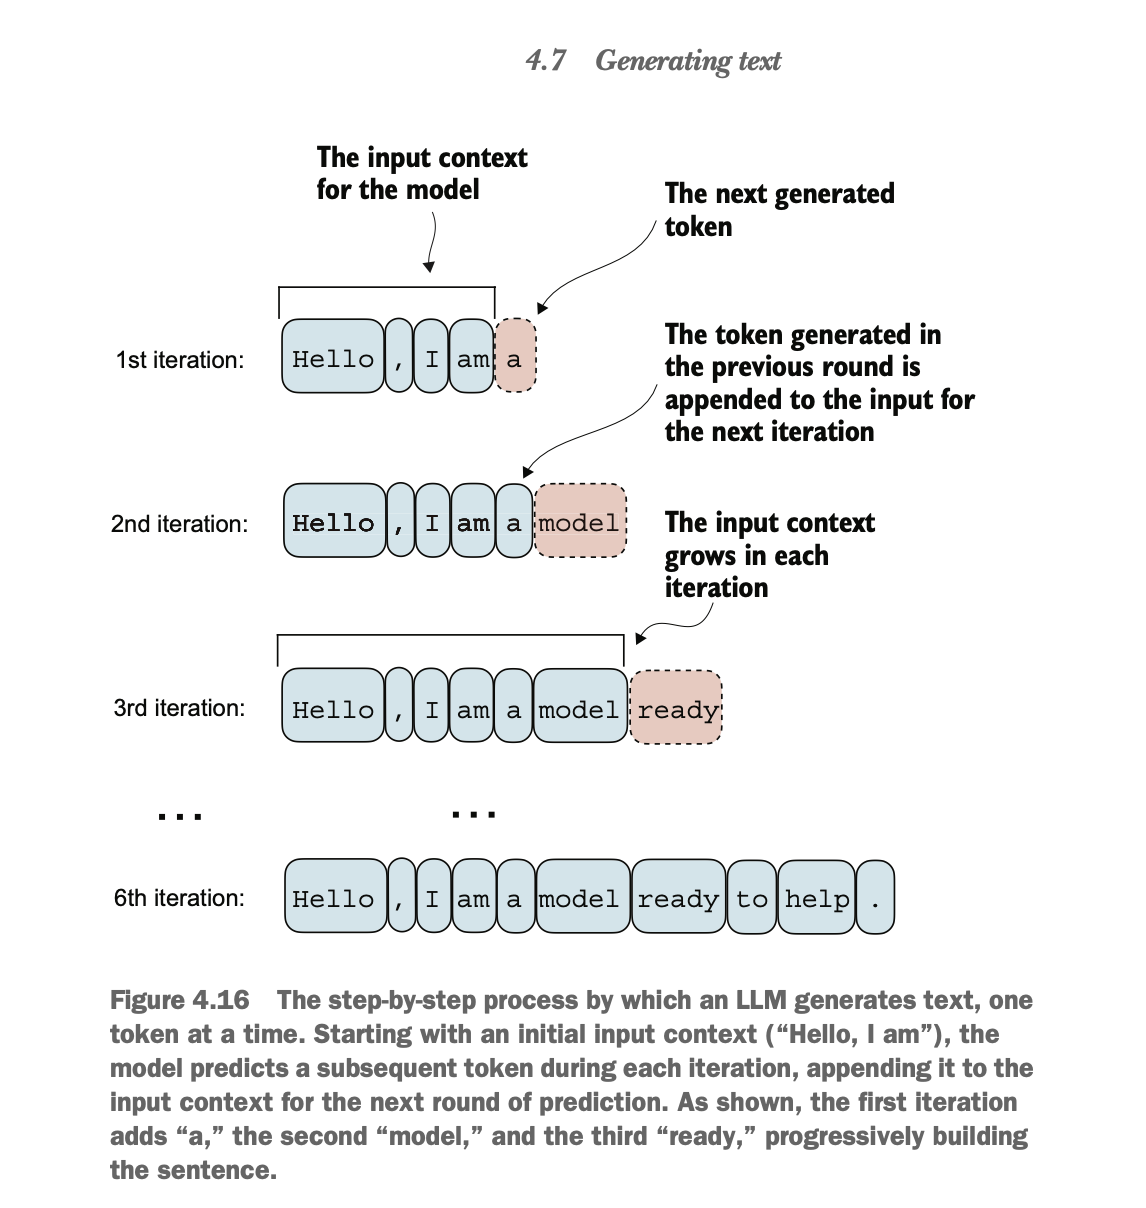


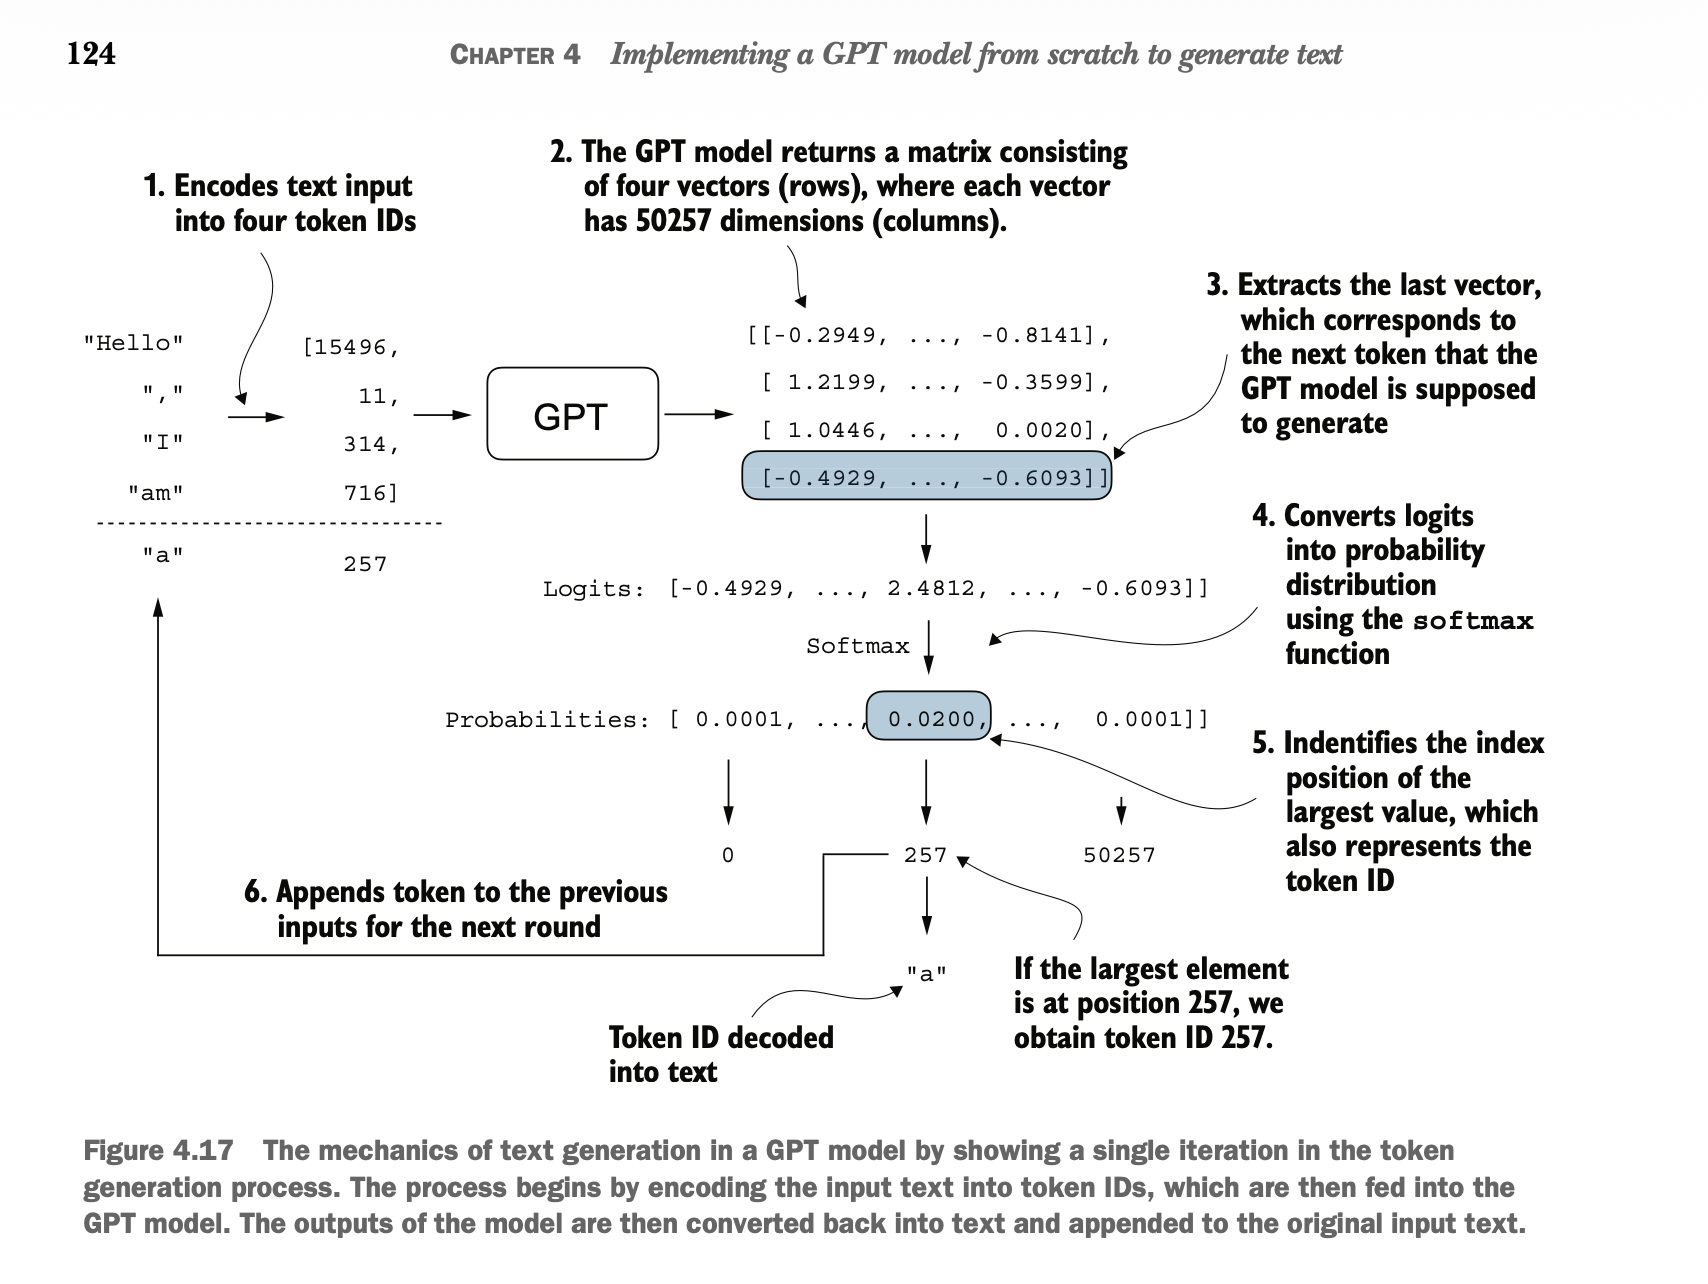


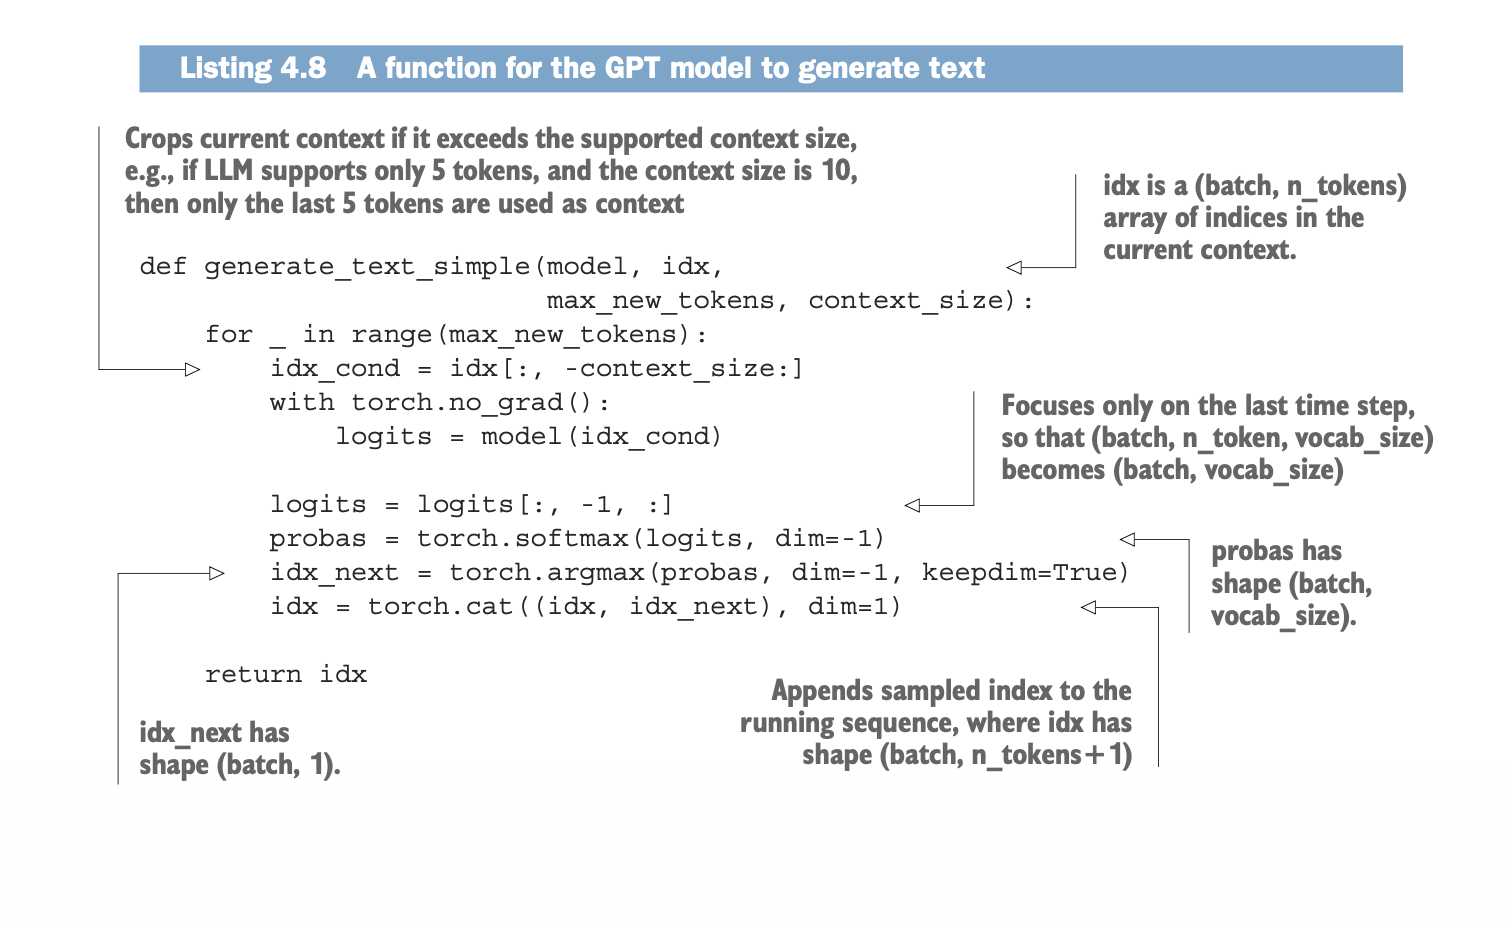


In [46]:
def generate_text_simple(model, idx, max_new_tokens, context_size):

    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]

        # Get the predictions:
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch,vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        idx = torch.cat((idx, idx_next), dim=1)  # (batch,n_tokens+1)

    return idx

In [45]:
# Let’s now try out the generate_text_simple function with the "Hello, I am" con-
# text as model input. First, we encode the input context into token IDs:

start_context = "Hello, I am"

encoded = tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor = torch.tensor(encoded).unsqueeze(0)  # adds batch dimension
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


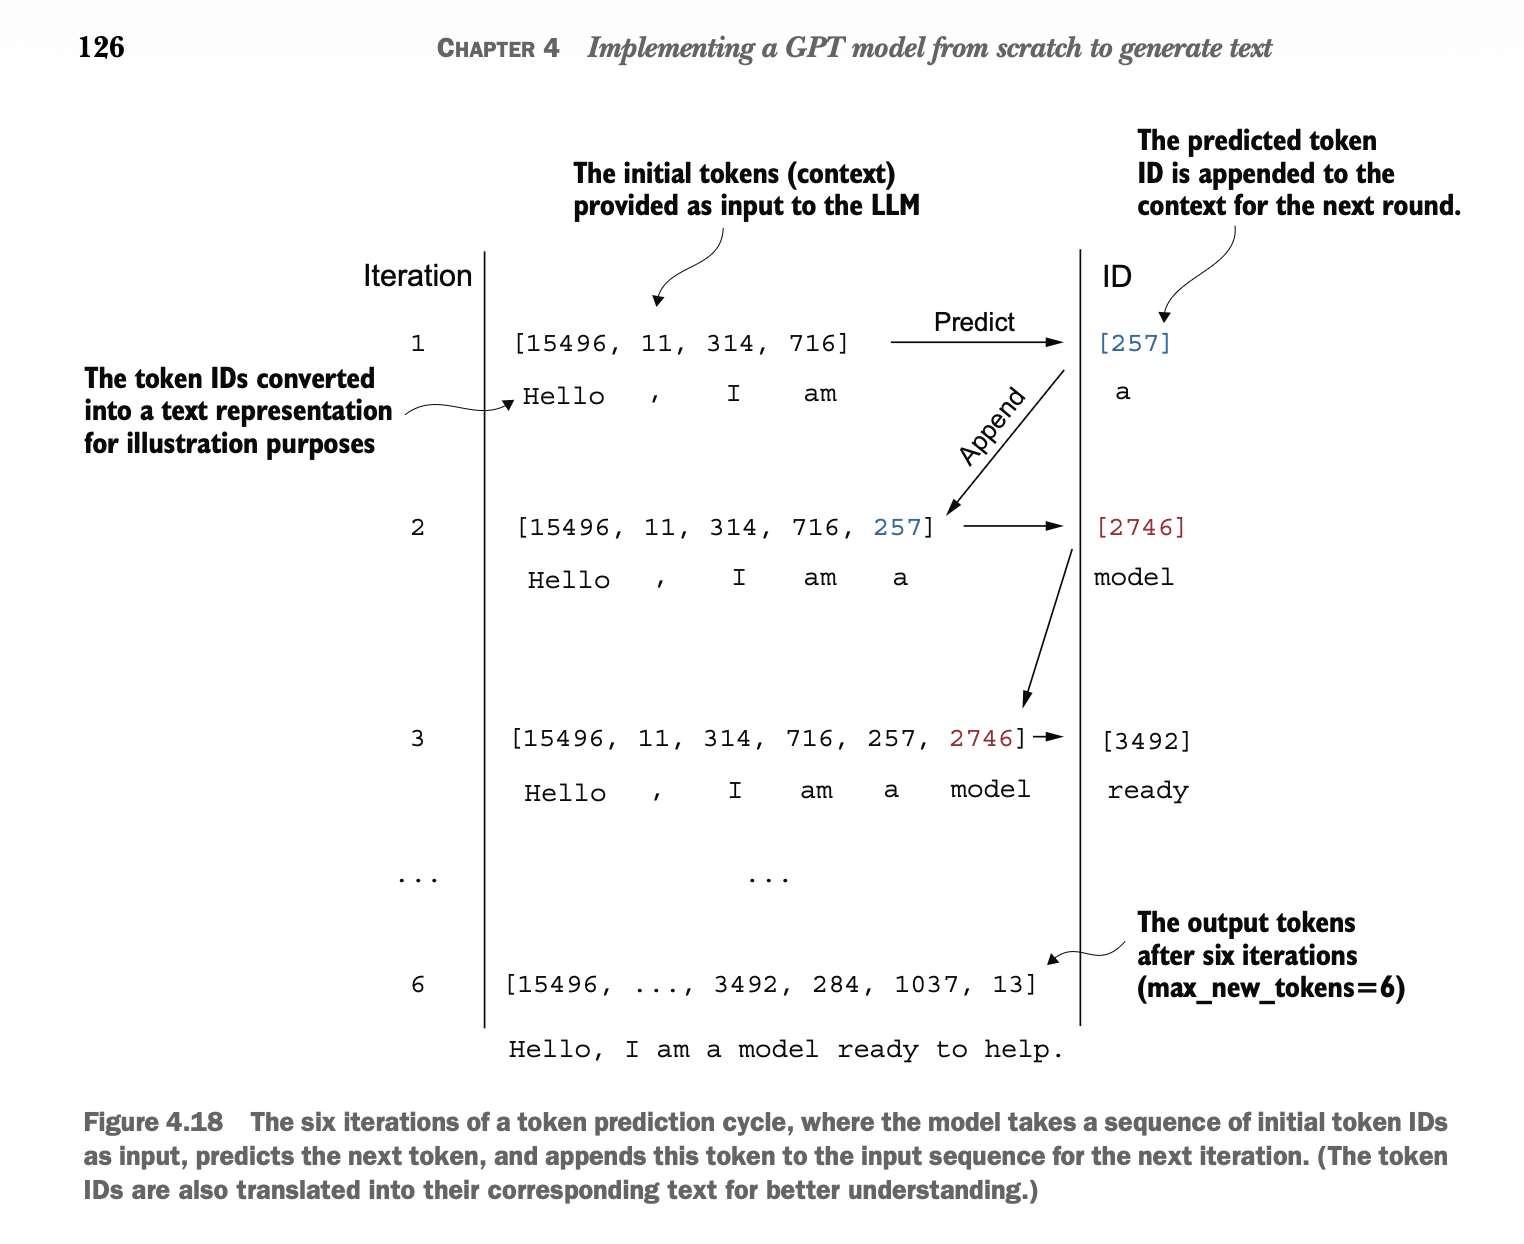


In [ ]:
# Next, we put the model into .eval() mode. This disables random components like
# dropout, which are only used during training, and use the generate_text_simple
# function on the encoded input tensor:

model.eval()
output = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"],
)
print("Output:", output)
print("Output length:", len(output[0]))

# The resulting output token IDs are :

# Output: tensor([[15496, 11, 314, 716, 27018, 24086, 47843,
# 30961, 42348, 7267]])
# Output length: 10
print()
# Using the .decode method of the tokenizer, we can convert the IDs back into text:
decoded_text = tokenizer.decode(output.squeeze(0).tolist())
print(decoded_text)

# The model output in text format is :
# Hello, I am Featureiman Byeswickattribute argue

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10
Hello, I am Featureiman Byeswickattribute argue


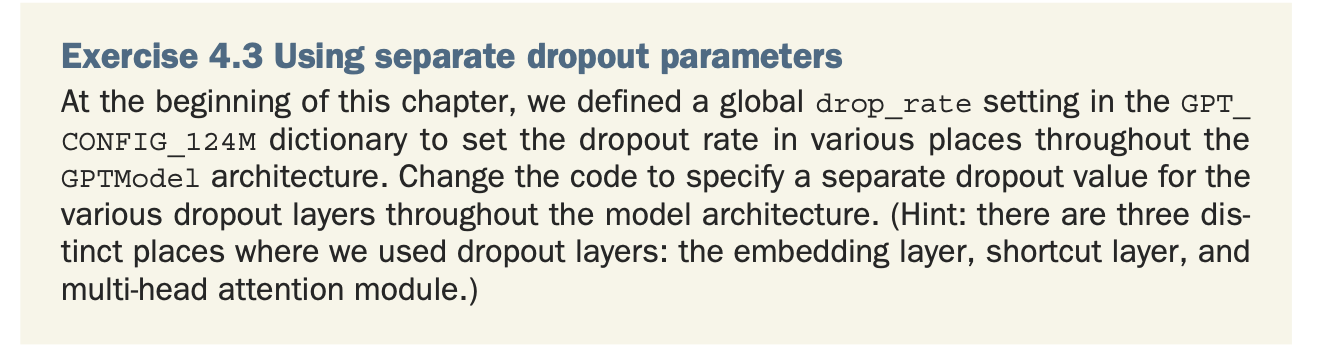


In [ ]:
# Solution :

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate_emb": 0.1,  # NEW: dropout for embedding layers
    "drop_rate_attn": 0.1,  # NEW: dropout for multi-head attention
    "drop_rate_shortcut": 0.1,  # NEW: dropout for shortcut connections
    "qkv_bias": False,
}

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate_attn"],  # NEW: dropout for multi-head attention
            qkv_bias=cfg["qkv_bias"],
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate_shortcut"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed-forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(
            cfg["drop_rate_emb"]
        )  # NEW: dropout for embedding layers

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)